# Phase 1 — Perception Pipeline (clean, final version)

This notebook contains only the validated, active pipeline for the perception phase: build prototypes from annotated frames, classify with a confidence threshold, correct the pants/shoe confusion with a geometric descriptor, and run the whole thing on video.

## Setup

In [10]:
import os
import time
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
from scipy import ndimage
from transformers import AutoModel, CLIPImageProcessor

%pip install shapely pandas -q
from shapely.geometry import Point, Polygon
import json
import pandas as pd


Note: you may need to restart the kernel to use updated packages.


In [11]:
# Load C-RADIOv4 model, with timing
local_repo = "../models/c_radio_weights"

if not os.path.exists(local_repo):
    print(f"ERROR: Cannot find the directory at:\n{os.path.abspath(local_repo)}")
else:
    print(f"Loading model from local path: {os.path.abspath(local_repo)}...")
    t0 = time.time()

    image_processor = CLIPImageProcessor.from_pretrained(local_repo)
    model = AutoModel.from_pretrained(local_repo, trust_remote_code=True)
    model.eval().cuda()
    torch.cuda.synchronize()

    print(f"Model loaded successfully into VRAM! Total: {time.time() - t0:.2f}s")

patch_size = model.patch_size if hasattr(model, 'patch_size') else 16


Loading model from local path: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights...


Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Model loaded successfully into VRAM! Total: 3.98s


In [12]:
def extract_spatial_features(pil_image):
    """
    Input: a PIL image (RGB)
    Output:
    - spatial_features: torch tensor [1, C, h_feat, w_feat]
    - h_feat, w_feat: number of rows/columns in the patch grid
    - resized_size: (nearest_w, nearest_h), the resolution the image was actually
      resized to before entering the model
    """
    nearest_h, nearest_w = model.get_nearest_supported_resolution(
        height=pil_image.height, width=pil_image.width
    )
    image_resized = pil_image.resize((nearest_w, nearest_h), Image.Resampling.LANCZOS)

    inputs = image_processor(images=image_resized, return_tensors='pt', do_resize=False)
    pixel_values = inputs.pixel_values.to(dtype=torch.bfloat16, device='cuda')

    with torch.no_grad():
        with torch.autocast('cuda', dtype=torch.bfloat16):
            summary, features = model(pixel_values)

    h_feat = nearest_h // patch_size
    w_feat = nearest_w // patch_size
    from einops import rearrange
    spatial_features = rearrange(features, 'b (h w) d -> b d h w', h=h_feat, w=w_feat)

    return spatial_features, h_feat, w_feat, (nearest_w, nearest_h)


## Reference frames and prototypes

Eight annotated frames, chosen to cover different *states* of each piece (isolated on the table, partially assembled, fully assembled) rather than just different angles — that distinction is what actually mattered for generalization. `caos_f0211.json` also carries the `hand` annotations; its `shoe`/`pants` polygons are excluded on purpose (see note below).

In [13]:
ALL_REFERENCE_FRAMES = [
    ("../data/extracted_frames/1_disassembled_controlled_caos_f0001.jpg",
     "../data/extracted_frames/1_disassembled_controlled_caos_f0001.json"),
    ("../data/extracted_frames/caos_f0149.jpg",
     "../data/extracted_frames/caos_f0149.json"),
    ("../data/extracted_frames/5_assembled_f0002.jpg",
     "../data/extracted_frames/5_assembled_f0002.json"),
    ("../data/extracted_frames/5_assembled_f0019.jpg",
     "../data/extracted_frames/5_assembled_f0019.json"),
    ("../data/extracted_frames/caos_f0211.jpg",
     "../data/extracted_frames/caos_f0211.json"),
    ("../data/extracted_frames/2_disassembled_caos_f0016.jpg",
     "../data/extracted_frames/2_disassembled_caos_f0016.json"),
    ("../data/extracted_frames/3_disassembled_ordered_f0001.jpg",
     "../data/extracted_frames/3_disassembled_ordered_f0001.json"),
    ("../data/extracted_frames/1_disassembled_controlled_caos_f0016.jpg",
     "../data/extracted_frames/1_disassembled_controlled_caos_f0016.json"),
]

EXCLUDE_LABELS_PER_FRAME = {
    "../data/extracted_frames/caos_f0211.json": {"shoe", "pants"}
}

In [14]:
def build_prototypes_filtered(reference_frames, exclude_labels_per_frame, verbose=True):
    """
    Build one prototype (mean feature vector) per label, pooling annotated patches across
    every reference frame. Patches whose label is excluded for a given frame are skipped
    entirely — neither counted as that label nor dumped into 'background'.
    """
    label_to_vectors = {}
    label_to_frame_counts = {}

    for image_path, json_path in reference_frames:
        reference_image = Image.open(image_path).convert("RGB")
        ref_features, ref_h_feat, ref_w_feat, (ref_resized_w, ref_resized_h) = extract_spatial_features(reference_image)
        ref_features_np = ref_features.squeeze(0).permute(1, 2, 0).float().cpu().numpy()

        with open(json_path) as f:
            annotations = json.load(f)
        scale_x = ref_resized_w / annotations["imageWidth"]
        scale_y = ref_resized_h / annotations["imageHeight"]
        exclude = exclude_labels_per_frame.get(json_path, set())
        polygons = [(s["label"], Polygon(s["points"])) for s in annotations["shapes"]]

        frame_patch_labels = np.full((ref_h_feat, ref_w_feat), "background", dtype=object)
        for row in range(ref_h_feat):
            for col in range(ref_w_feat):
                cx = ((col + 0.5) * patch_size) / scale_x
                cy = ((row + 0.5) * patch_size) / scale_y
                point = Point(cx, cy)
                for label, polygon in polygons:
                    if polygon.contains(point):
                        frame_patch_labels[row, col] = "__ignore__" if label in exclude else label
                        break

        for label in set(frame_patch_labels.flatten()):
            if label == "__ignore__":
                continue
            mask = (frame_patch_labels == label)
            n = int(mask.sum())
            label_to_vectors.setdefault(label, []).append(ref_features_np[mask])
            label_to_frame_counts.setdefault(label, []).append((json_path.split("/")[-1], n))

    prototypes_out = {label: np.concatenate(chunks, axis=0).mean(axis=0) for label, chunks in label_to_vectors.items()}

    if verbose:
        print("=== Ground truth behind each prototype: patches per frame ===")
        for label in sorted(label_to_frame_counts):
            total = sum(n for _, n in label_to_frame_counts[label])
            print(f"\n'{label}': {total} total patches, from {len(label_to_frame_counts[label])} frame(s)")
            for frame_name, n in label_to_frame_counts[label]:
                print(f"   {frame_name}: {n} patches")

    return prototypes_out


prototypes_final = build_prototypes_filtered(ALL_REFERENCE_FRAMES, EXCLUDE_LABELS_PER_FRAME)


=== Ground truth behind each prototype: patches per frame ===

'arm_1': 44 total patches, from 7 frame(s)
   1_disassembled_controlled_caos_f0001.json: 5 patches
   caos_f0149.json: 16 patches
   5_assembled_f0002.json: 5 patches
   5_assembled_f0019.json: 6 patches
   2_disassembled_caos_f0016.json: 5 patches
   3_disassembled_ordered_f0001.json: 6 patches
   1_disassembled_controlled_caos_f0016.json: 1 patches

'arm_2': 19 total patches, from 6 frame(s)
   1_disassembled_controlled_caos_f0001.json: 2 patches
   5_assembled_f0002.json: 4 patches
   5_assembled_f0019.json: 4 patches
   2_disassembled_caos_f0016.json: 2 patches
   3_disassembled_ordered_f0001.json: 5 patches
   1_disassembled_controlled_caos_f0016.json: 2 patches

'background': 31081 total patches, from 8 frame(s)
   1_disassembled_controlled_caos_f0001.json: 3970 patches
   caos_f0149.json: 3929 patches
   5_assembled_f0002.json: 3999 patches
   5_assembled_f0019.json: 3985 patches
   caos_f0211.json: 3402 patches
   2

## Visual check: what is each prototype actually learning from?


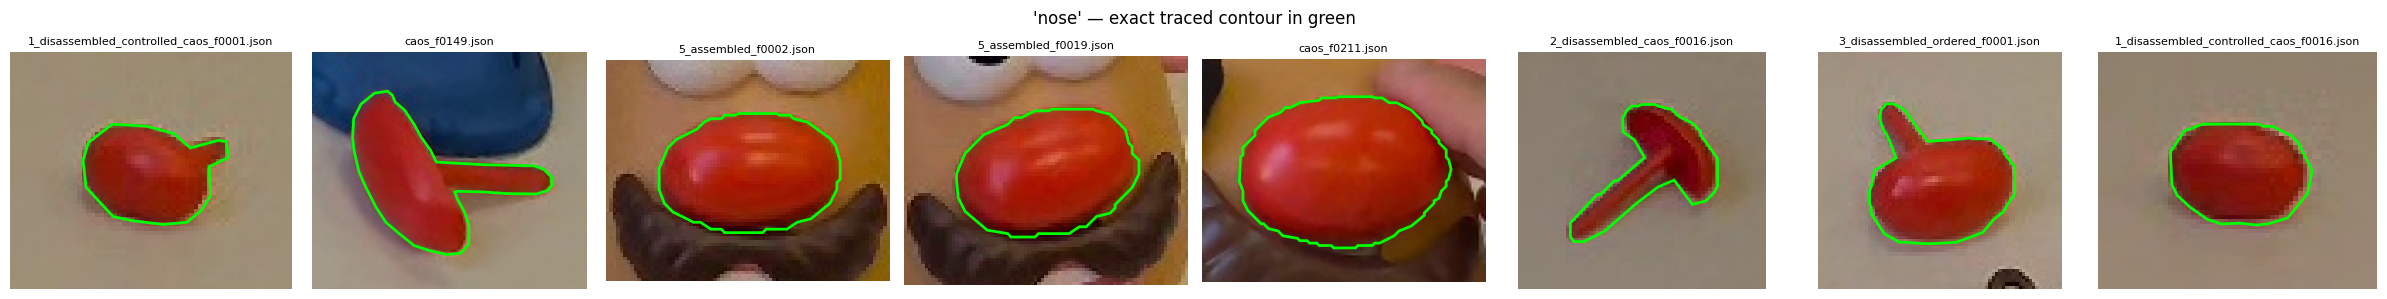

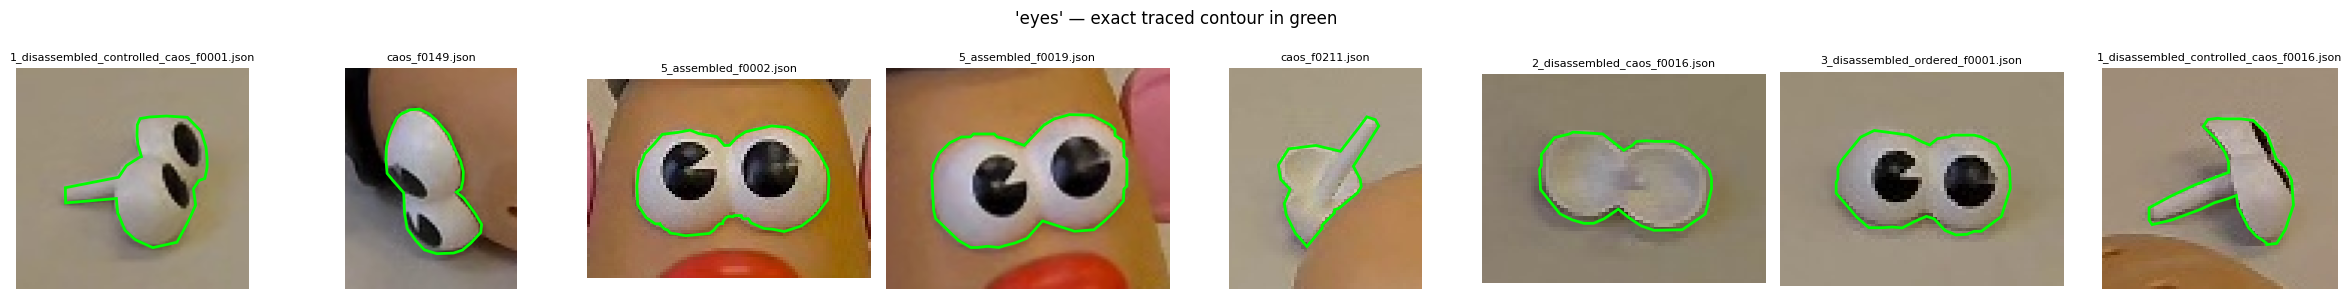

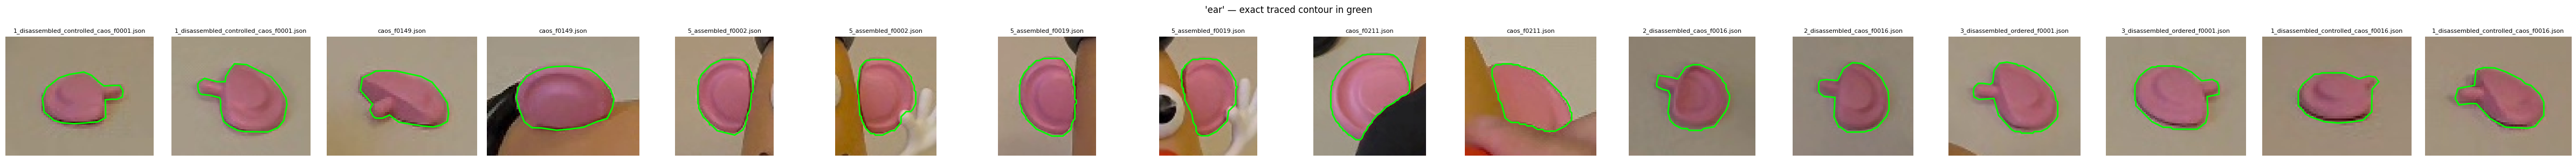

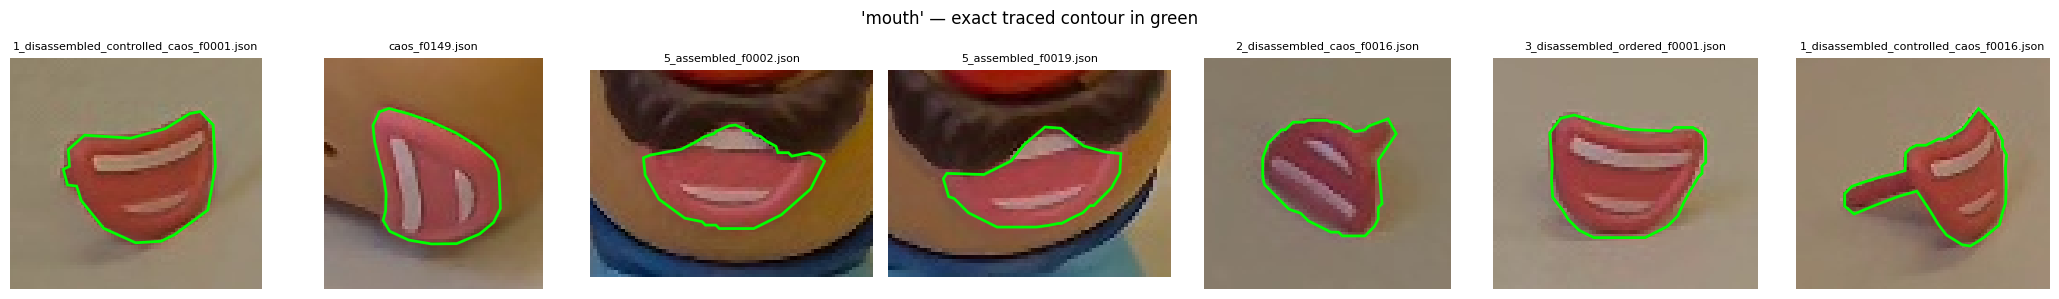

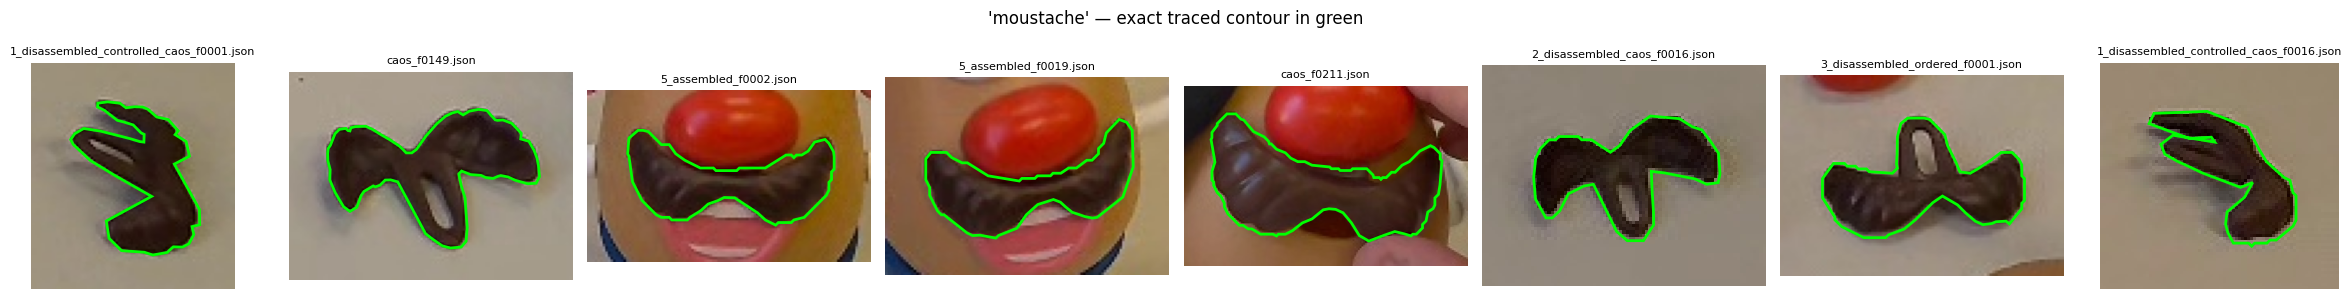

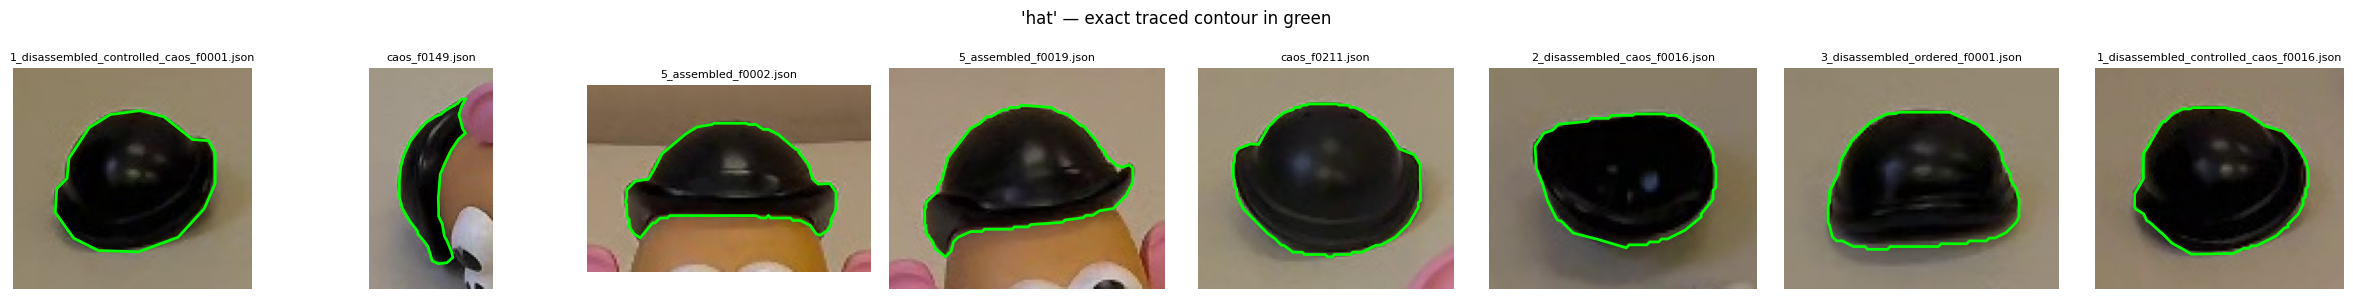

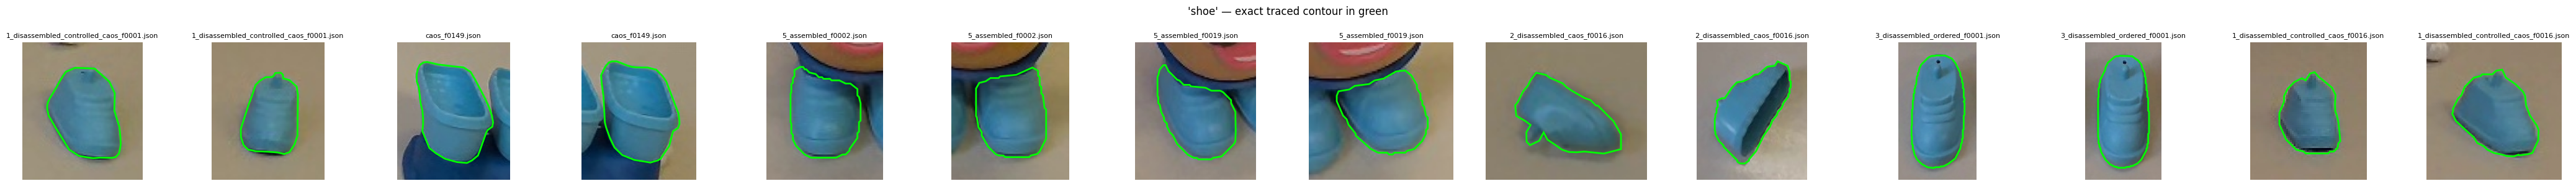

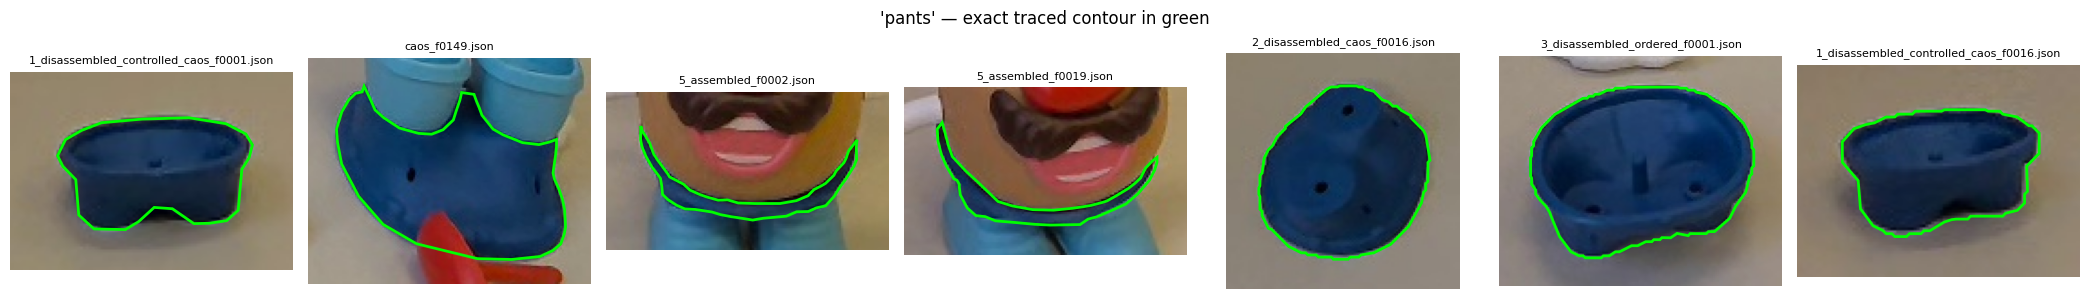

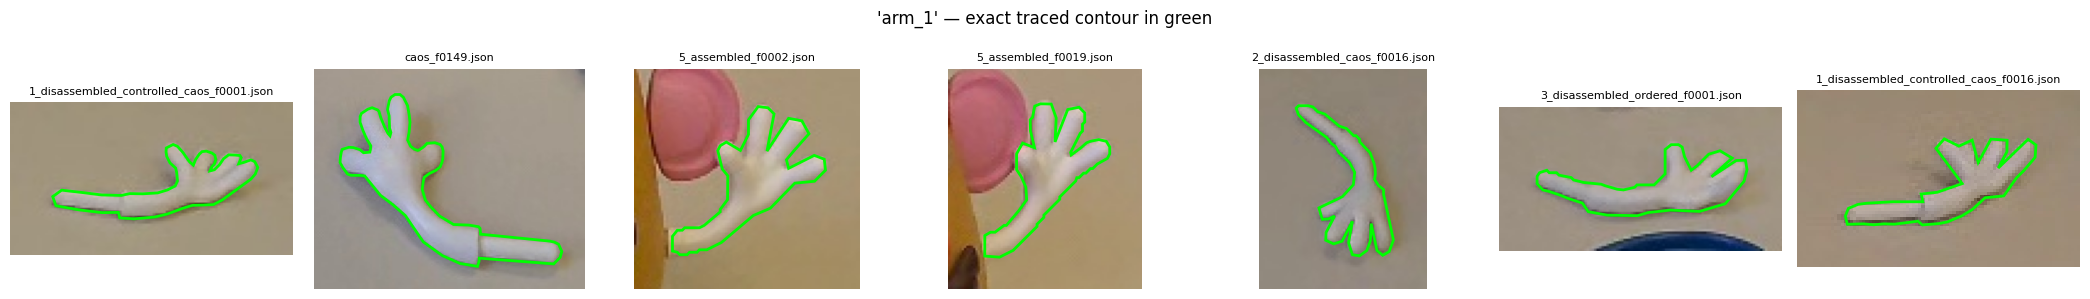

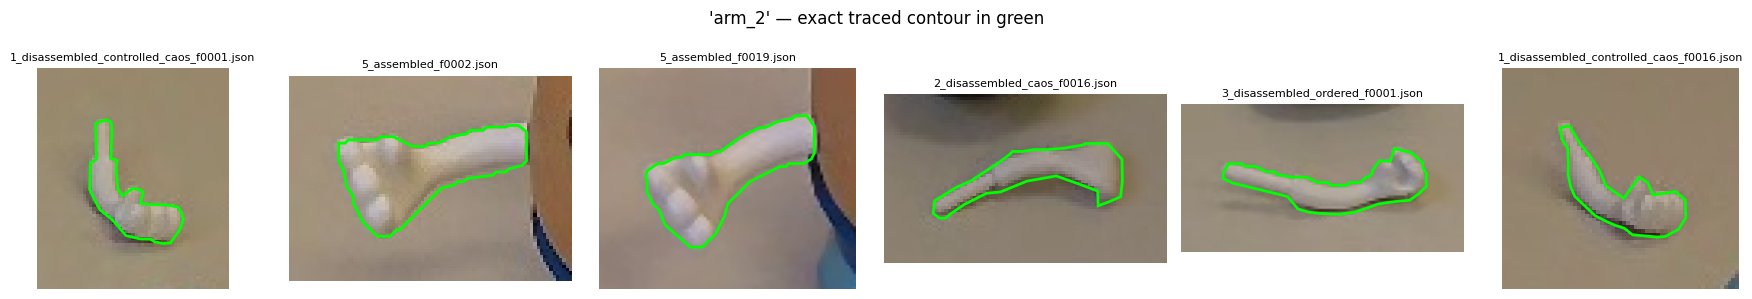

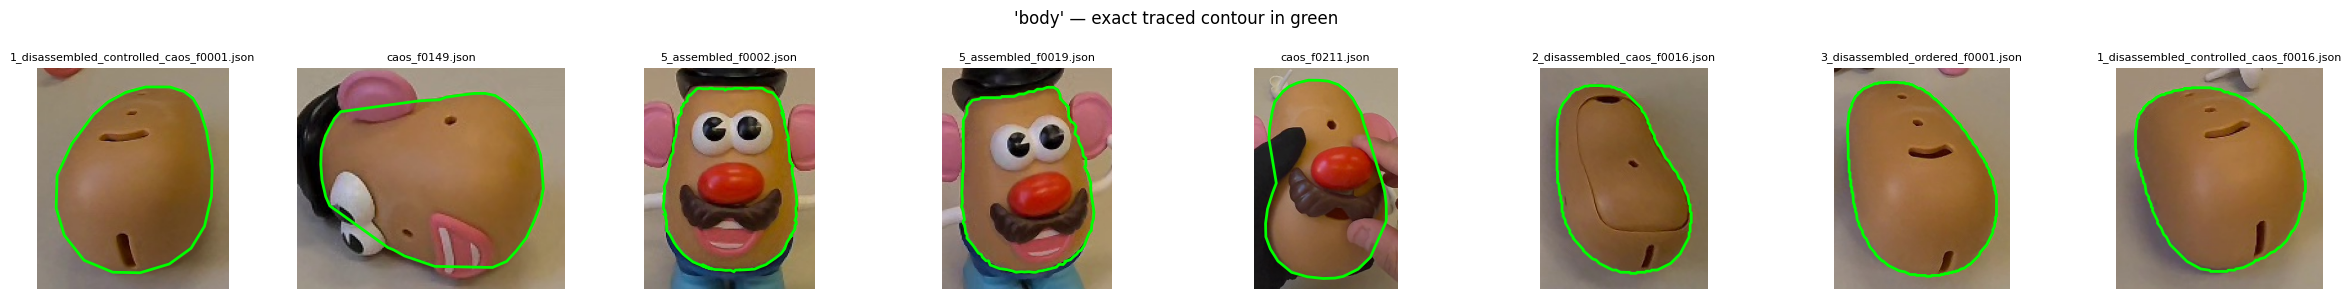

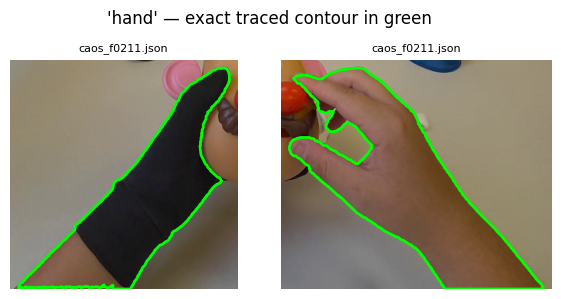

In [15]:
def show_polygon_crops_with_outline(reference_frames, target_label, exclude_labels_per_frame=None, padding=15):
    exclude_labels_per_frame = exclude_labels_per_frame or {}
    items = []

    for image_path, json_path in reference_frames:
        excluded = exclude_labels_per_frame.get(json_path, set())
        if target_label in excluded:
            continue

        with open(json_path) as f:
            annotations = json.load(f)

        image = Image.open(image_path).convert("RGB")
        for shape in annotations["shapes"]:
            if shape["label"] != target_label:
                continue
            poly = Polygon(shape["points"])
            minx, miny, maxx, maxy = poly.bounds
            minx, miny = max(0, int(minx) - padding), max(0, int(miny) - padding)
            maxx, maxy = min(image.width, int(maxx) + padding), min(image.height, int(maxy) + padding)
            crop = image.crop((minx, miny, maxx, maxy))
            shifted_points = [(x - minx, y - miny) for x, y in shape["points"]]
            frame_name = json_path.split("/")[-1]
            items.append((frame_name, crop, shifted_points))

    n = len(items)
    if n == 0:
        print(f"No instances of '{target_label}' to show.")
        return
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))
    if n == 1:
        axes = [axes]
    for ax, (frame_name, crop, points) in zip(axes, items):
        ax.imshow(crop)
        poly_patch = mpatches.Polygon(points, closed=True, fill=False, edgecolor="lime", linewidth=2)
        ax.add_patch(poly_patch)
        ax.set_title(frame_name, fontsize=8)
        ax.axis("off")
    plt.suptitle(f"'{target_label}' — exact traced contour in green")
    plt.tight_layout()
    plt.show()


ALL_LABELS = ['nose', 'eyes', 'ear', 'mouth', 'moustache', 'background', 'hat', 'shoe', 'pants', 'arm_1', 'arm_2', 'body', 'hand']

for label in ALL_LABELS:
    if label == "background":
        continue
    show_polygon_crops_with_outline(ALL_REFERENCE_FRAMES, label, EXCLUDE_LABELS_PER_FRAME)


## Prototype similarity matrix

Which classes does C-RADIO confuse by appearance alone?

In [16]:
_cmap = plt.get_cmap("tab20")
GLOBAL_LABEL_TO_COLOR = {label: _cmap(i / len(ALL_LABELS))[:3] for i, label in enumerate(ALL_LABELS)}
GLOBAL_LABEL_TO_COLOR["background"] = (0.85, 0.85, 0.85)

def normalize(v):
    return v / (np.linalg.norm(v, axis=-1, keepdims=True) + 1e-8)

label_order = list(prototypes_final.keys())
proto_matrix = normalize(np.stack([prototypes_final[l] for l in label_order]))
sim_matrix = proto_matrix @ proto_matrix.T
sim_df = pd.DataFrame(sim_matrix, index=label_order, columns=label_order)
print(sim_df.round(2))


            body   hat  background  pants  eyes  arm_1  mouth  nose  shoe  \
body        1.00  0.81        0.69   0.85  0.81   0.74   0.83  0.85  0.82   
hat         0.81  1.00        0.64   0.87  0.77   0.72   0.82  0.80  0.81   
background  0.69  0.64        1.00   0.68  0.60   0.60   0.63  0.62  0.66   
pants       0.85  0.87        0.68   1.00  0.79   0.77   0.85  0.83  0.91   
eyes        0.81  0.77        0.60   0.79  1.00   0.80   0.85  0.82  0.77   
arm_1       0.74  0.72        0.60   0.77  0.80   1.00   0.82  0.77  0.77   
mouth       0.83  0.82        0.63   0.85  0.85   0.82   1.00  0.87  0.83   
nose        0.85  0.80        0.62   0.83  0.82   0.77   0.87  1.00  0.81   
shoe        0.82  0.81        0.66   0.91  0.77   0.77   0.83  0.81  1.00   
arm_2       0.76  0.76        0.63   0.79  0.83   0.96   0.86  0.79  0.80   
moustache   0.83  0.80        0.63   0.82  0.82   0.81   0.89  0.88  0.81   
ear         0.83  0.81        0.64   0.83  0.84   0.81   0.88  0.87  0.82   

## Classification with a confidence threshold

Nearest-prototype by cosine similarity, but patches whose best match doesn't clear `background` by a margin fall back to `background` — otherwise noisy patches on empty wall/table occasionally get assigned to a real class ('phantom' objects).

In [17]:
def classify_with_confidence(test_image_path, prototypes, confidence_margin=0.03): #test sul parametro di threshold
    label_names = list(prototypes.keys())
    proto_matrix = normalize(np.stack([prototypes[l] for l in label_names]))

    test_image = Image.open(test_image_path).convert("RGB")
    test_features, h_feat, w_feat, _ = extract_spatial_features(test_image)
    test_features_np = test_features.squeeze(0).permute(1, 2, 0).float().cpu().numpy()

    sims = normalize(test_features_np.reshape(-1, test_features_np.shape[-1])) @ proto_matrix.T
    best_idx = sims.argmax(axis=1)
    best_sim = sims.max(axis=1)
    bg_sim = sims[:, label_names.index("background")]
    predicted_flat = np.array(label_names)[best_idx]

    uncertain = (best_sim - bg_sim) < confidence_margin
    predicted_flat[uncertain] = "background"

    return predicted_flat.reshape(h_feat, w_feat)


def classify_and_plot(test_image_path, prototypes, title_suffix="", confidence_margin=0.03):
    predicted_labels = classify_with_confidence(test_image_path, prototypes, confidence_margin)
    h_feat, w_feat = predicted_labels.shape
    test_image = Image.open(test_image_path).convert("RGB")

    color_grid = np.zeros((h_feat, w_feat, 3))
    for row in range(h_feat):
        for col in range(w_feat):
            color_grid[row, col] = GLOBAL_LABEL_TO_COLOR[predicted_labels[row, col]]
    color_grid_resized = cv2.resize(color_grid, test_image.size, interpolation=cv2.INTER_NEAREST)

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    axes[0].imshow(test_image)
    axes[0].set_title("Test image", fontsize=14)
    axes[0].axis("off")
    axes[1].imshow(color_grid_resized)
    axes[1].set_title(f"Predicted parts {title_suffix}", fontsize=14)
    axes[1].axis("off")
    legend_patches = [mpatches.Patch(color=GLOBAL_LABEL_TO_COLOR[l], label=l) for l in ALL_LABELS]
    axes[1].legend(handles=legend_patches, bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.show()
    return predicted_labels


## Geometric descriptor: pants vs shoe shape correction

Appearance alone can't separate `pants` from `shoe` (0.91 similarity) — but shape does. Rounded `pants` vs boot-shaped `shoe` give distinct aspect ratios on the minimum bounding rectangle (1.79–2.51 vs 1.02–1.58; threshold 1.7). The correction assigns one label per connected pants/shoe blob, not per fragment, to avoid contradictory labels on the same object.

Refined after testing: blobs that are too small, too large (likely two real pieces already fused, e.g. shoes plugged into the pants base), or too close to the threshold are left with their original appearance-based label instead of being forced. This fixed the earlier failure mode where a fused pants+shoe object got collapsed into one wrong label.

In [18]:
PANTS_SHOE_AR_THRESHOLD = 1.7

def correct_pants_shoe_with_shape(predicted_labels, ar_threshold=PANTS_SHOE_AR_THRESHOLD,
                                    uncertainty_band=0.2, min_patches_to_correct=8,
                                    max_single_object_patches=60):
    corrected = predicted_labels.copy()
    combined_mask = np.isin(predicted_labels, ["pants", "shoe"]).astype(np.uint8)
    labeled_blobs, n_blobs = ndimage.label(combined_mask, structure=np.ones((3, 3)))
    for blob_id in range(1, n_blobs + 1):
        blob_mask = (labeled_blobs == blob_id).astype(np.uint8)
        size = blob_mask.sum()
        if size < min_patches_to_correct or size > max_single_object_patches:
            continue  # too small to trust the shape, or too large — likely fused, leave appearance label as is
        contours, _ = cv2.findContours(blob_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if not contours:
            continue
        contour = max(contours, key=cv2.contourArea)
        if len(contour) < 3:
            continue
        rect = cv2.minAreaRect(contour)
        w_, h_ = rect[1]
        if min(w_, h_) == 0:
            continue
        ar = max(w_, h_) / min(w_, h_)
        if abs(ar - ar_threshold) < uncertainty_band:
            continue
        corrected[blob_mask.astype(bool)] = "pants" if ar >= ar_threshold else "shoe"
    return corrected


def blob_shape_descriptors(predicted_labels, target_labels):
    """One row per connected blob among target_labels: majority appearance-label, size,
    aspect ratio, and contour-defect count (useful for arm_1/arm_2, not reliable on the
    coarse grid — kept here for completeness, see notebook history)."""
    mask = np.isin(predicted_labels, list(target_labels)).astype(np.uint8)
    labeled_mask, n_blobs = ndimage.label(mask, structure=np.ones((3, 3)))
    results = []
    for blob_id in range(1, n_blobs + 1):
        blob_mask = (labeled_mask == blob_id).astype(np.uint8)
        if blob_mask.sum() < 3:
            continue
        contours, _ = cv2.findContours(blob_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if not contours:
            continue
        contour = max(contours, key=cv2.contourArea)
        if len(contour) < 3:
            continue
        labels_in_blob = predicted_labels[blob_mask.astype(bool)]
        values, counts = np.unique(labels_in_blob, return_counts=True)
        majority_label = values[np.argmax(counts)]
        rect = cv2.minAreaRect(contour)
        w_, h_ = rect[1]
        aspect_ratio = max(w_, h_) / min(w_, h_) if min(w_, h_) > 0 else 0
        n_defects = 0
        hull_idx = cv2.convexHull(contour, returnPoints=False)
        if hull_idx is not None and len(hull_idx) >= 3:
            try:
                defects = cv2.convexityDefects(contour, hull_idx)
            except cv2.error:
                defects = None
            if defects is not None:
                scale = np.sqrt(cv2.contourArea(contour)) or 1.0
                depths = (defects.reshape(-1, 4)[:, 3] / 256.0) / scale
                n_defects = int((depths > 0.05).sum())
        results.append({
            "majority_label": majority_label,
            "n_patches": int(blob_mask.sum()),
            "aspect_ratio": round(aspect_ratio, 2),
            "n_defects": n_defects,
        })
    return results


### Verify the correction 

Pick a representative test frame — ideally one with several loose pants/shoe pieces, not one used for the prototypes — and check that `majority_label` and `aspect_ratio` agree after correction.

In [19]:
TEST_FRAME_FOR_SHAPE_CHECK = "../data/extracted_frames/2_disassembled_caos_f0023.jpg"

predicted_check = classify_with_confidence(TEST_FRAME_FOR_SHAPE_CHECK, prototypes_final)
predicted_corrected = correct_pants_shoe_with_shape(predicted_check)

print("=== pants/shoe blobs BEFORE shape correction ===")
for r in blob_shape_descriptors(predicted_check, {"pants", "shoe"}):
    print(r)

print("\n=== pants/shoe blobs AFTER shape correction ===")
for r in blob_shape_descriptors(predicted_corrected, {"pants", "shoe"}):
    print(r)


=== pants/shoe blobs BEFORE shape correction ===
{'majority_label': np.str_('pants'), 'n_patches': 19, 'aspect_ratio': 1.67, 'n_defects': 1}
{'majority_label': np.str_('pants'), 'n_patches': 7, 'aspect_ratio': 2.67, 'n_defects': 1}
{'majority_label': np.str_('pants'), 'n_patches': 22, 'aspect_ratio': 1.0, 'n_defects': 0}
{'majority_label': np.str_('pants'), 'n_patches': 21, 'aspect_ratio': 1.4, 'n_defects': 1}
{'majority_label': np.str_('shoe'), 'n_patches': 3, 'aspect_ratio': 5.0, 'n_defects': 1}

=== pants/shoe blobs AFTER shape correction ===
{'majority_label': np.str_('pants'), 'n_patches': 19, 'aspect_ratio': 1.67, 'n_defects': 1}
{'majority_label': np.str_('pants'), 'n_patches': 7, 'aspect_ratio': 2.67, 'n_defects': 1}
{'majority_label': np.str_('shoe'), 'n_patches': 22, 'aspect_ratio': 1.0, 'n_defects': 0}
{'majority_label': np.str_('shoe'), 'n_patches': 21, 'aspect_ratio': 1.4, 'n_defects': 1}
{'majority_label': np.str_('shoe'), 'n_patches': 3, 'aspect_ratio': 5.0, 'n_defects':

## Video pipeline

A cheap, content-agnostic motion signal (frame differencing on the central 50% of the image — robust to head/camera panning) decides when the scene is likely still. C-RADIO is invoked only on stillness-entry events, not on every frame — the same pattern the final real-time system will use, not just a demo convenience.

In [20]:
def compute_motion_score(frame_bgr, prev_gray_crop, resize_to=(320, 320)):
    """Returns (motion_score, current_gray_crop). motion_score is None on the first frame."""
    small = cv2.resize(frame_bgr, resize_to)
    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    h, w = gray.shape
    crop = gray[h//4:h - h//4, w//4:w - w//4]
    if prev_gray_crop is None:
        return None, crop
    diff = cv2.absdiff(crop, prev_gray_crop)
    return diff.mean(), crop


In [21]:
MIN_BLOB_PATCHES = 5

def annotate_frame(frame_bgr, status, predicted_labels=None):
    """Draws the colored overlay + one name per detected object. Hand patches are shown
    with no tint at all (not even background tint) — hands are not a piece to report."""
    overlay = frame_bgr.copy()
    if status == "locked" and predicted_labels is not None:
        h_feat, w_feat = predicted_labels.shape
        scale_x = frame_bgr.shape[1] / w_feat
        scale_y = frame_bgr.shape[0] / h_feat

        color_grid = np.zeros((h_feat, w_feat, 3), dtype=np.uint8)
        for row in range(h_feat):
            for col in range(w_feat):
                label = predicted_labels[row, col]
                c = GLOBAL_LABEL_TO_COLOR["background"] if label == "hand" else GLOBAL_LABEL_TO_COLOR[label]
                color_grid[row, col] = (int(c[2]*255), int(c[1]*255), int(c[0]*255))
        color_grid_resized = cv2.resize(color_grid, (frame_bgr.shape[1], frame_bgr.shape[0]), interpolation=cv2.INTER_NEAREST)

        hand_mask = (predicted_labels == "hand").astype(np.uint8)
        hand_mask_resized = cv2.resize(hand_mask, (frame_bgr.shape[1], frame_bgr.shape[0]), interpolation=cv2.INTER_NEAREST).astype(bool)

        overlay = cv2.addWeighted(frame_bgr, 0.55, color_grid_resized, 0.45, 0)
        overlay[hand_mask_resized] = frame_bgr[hand_mask_resized]

        placed_positions = []
        for label in set(np.unique(predicted_labels)) - {"background", "hand"}:
            label_mask = (predicted_labels == label)
            labeled_blobs, n_blobs = ndimage.label(label_mask, structure=np.ones((3, 3)))
            for blob_id in range(1, n_blobs + 1):
                blob = (labeled_blobs == blob_id)
                if blob.sum() < MIN_BLOB_PATCHES:
                    continue
                rows, cols = np.where(blob)
                px, py = int(cols.mean() * scale_x), int(rows.mean() * scale_y)
                while any(abs(px - ex) < 55 and abs(py - ey) < 16 for ex, ey in placed_positions):
                    py += 16
                placed_positions.append((px, py))
                cv2.putText(overlay, label, (px - 25, py), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 3, cv2.LINE_AA)
                cv2.putText(overlay, label, (px - 25, py), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 1, cv2.LINE_AA)

        text, color = "LOCKED - classifying", (60, 200, 60)
    else:
        text, color = "scanning...", (60, 60, 220)

    cv2.rectangle(overlay, (0, 0), (overlay.shape[1], 40), (30, 30, 30), -1)
    cv2.putText(overlay, text, (12, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2, cv2.LINE_AA)
    return overlay


In [22]:
LEGEND_WIDTH = 220
LEGEND_LABELS = [l for l in ALL_LABELS if l not in ("background", "hand")]

def build_legend_panel(height, labels):
    panel = np.full((height, LEGEND_WIDTH, 3), (30, 30, 30), dtype=np.uint8)
    y = 30
    cv2.putText(panel, "Legend", (12, y), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
    y += 30
    for label in labels:
        c = GLOBAL_LABEL_TO_COLOR[label]
        bgr = (int(c[2]*255), int(c[1]*255), int(c[0]*255))
        cv2.rectangle(panel, (12, y - 12), (28, y + 2), bgr, -1)
        cv2.putText(panel, label, (36, y), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        y += 26
    return panel


In [ ]:
VIDEO_PATH = "../data/raw_videos/assembly_1.mp4"   # independent of the reference frames — no frame from this video was used for the prototypes
OUTPUT_PATH = "../outputs/perception_demo_correction_assembly_1.mp4"
MOTION_THRESHOLD = 1.0
STABLE_FRAMES_NEEDED = 5
CONFIDENCE_MARGIN = 0.03  
prototypes_for_demo = prototypes_final

os.makedirs(os.path.dirname(OUTPUT_PATH), exist_ok=True)

cap = cv2.VideoCapture(VIDEO_PATH)
assert cap.isOpened(), f"Could not open video at {VIDEO_PATH} — check the path"

fps = cap.get(cv2.CAP_PROP_FPS)
w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"Opened video: {w}x{h}, {fps:.1f}fps, {total_frames} frames")

writer = cv2.VideoWriter(OUTPUT_PATH, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w + LEGEND_WIDTH, h))
assert writer.isOpened(), f"Could not open VideoWriter for {OUTPUT_PATH}"

proto_names = list(prototypes_for_demo.keys())
proto_matrix_demo = normalize(np.stack([prototypes_for_demo[l] for l in proto_names]))

status = "scanning"
stable_count = 0
locked_labels = None
prev_gray_crop = None
frame_idx = 0

while True:
    ret, frame_bgr = cap.read()
    if not ret:
        break

    motion_score, prev_gray_crop = compute_motion_score(frame_bgr, prev_gray_crop)
    is_still = (motion_score is not None) and (motion_score < MOTION_THRESHOLD)

    if is_still:
        stable_count += 1
    else:
        stable_count = 0
        status = "scanning"
        locked_labels = None

    if stable_count >= STABLE_FRAMES_NEEDED and status == "scanning":
        pil_frame = Image.fromarray(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
        feats, hf, wf, _ = extract_spatial_features(pil_frame)
        feats_np = feats.squeeze(0).permute(1, 2, 0).float().cpu().numpy()
        sims = normalize(feats_np.reshape(-1, feats_np.shape[-1])) @ proto_matrix_demo.T

        best_idx = sims.argmax(axis=1)
        best_sim = sims.max(axis=1)
        bg_sim = sims[:, proto_names.index("background")]
        predicted_flat = np.array(proto_names)[best_idx]

        uncertain = (best_sim - bg_sim) < CONFIDENCE_MARGIN
        predicted_flat[uncertain] = "background"

        locked_labels = predicted_flat.reshape(hf, wf)
        locked_labels = correct_pants_shoe_with_shape(locked_labels)
        status = "locked"

    annotated = annotate_frame(frame_bgr, status, locked_labels)
    legend_panel = build_legend_panel(h, LEGEND_LABELS)
    writer.write(np.hstack([annotated, legend_panel]))
    frame_idx += 1
    if frame_idx % 300 == 0:
        print(f"{frame_idx}/{total_frames} frames processed...")

cap.release()
writer.release()
assert frame_idx > 0, "Zero frames were read — the video path was almost certainly wrong"
print(f"Done: {frame_idx} frames written to {OUTPUT_PATH}")


Opened video: 1024x1024, 30.0fps, 2348 frames
300/2348 frames processed...
600/2348 frames processed...
900/2348 frames processed...
1200/2348 frames processed...
1500/2348 frames processed...
1800/2348 frames processed...
2100/2348 frames processed...
Done: 2348 frames written to ../outputs/perception_demo_correction_assembly_1.mp4


In [24]:
import time

predicted_for_timing = classify_with_confidence(
    "../data/extracted_frames/2_disassembled_caos_f0023.jpg", prototypes_final
)

t0 = time.time()
for _ in range(50):
    _ = correct_pants_shoe_with_shape(predicted_for_timing)
t1 = time.time()
print(f"Average time per call: {(t1 - t0) / 50 * 1000:.2f} ms")

Average time per call: 0.25 ms


## Final snapshot: two clean, independent frames

Neither frame below was used to build the prototypes — pick your preferred disassembled and assembled examples here.

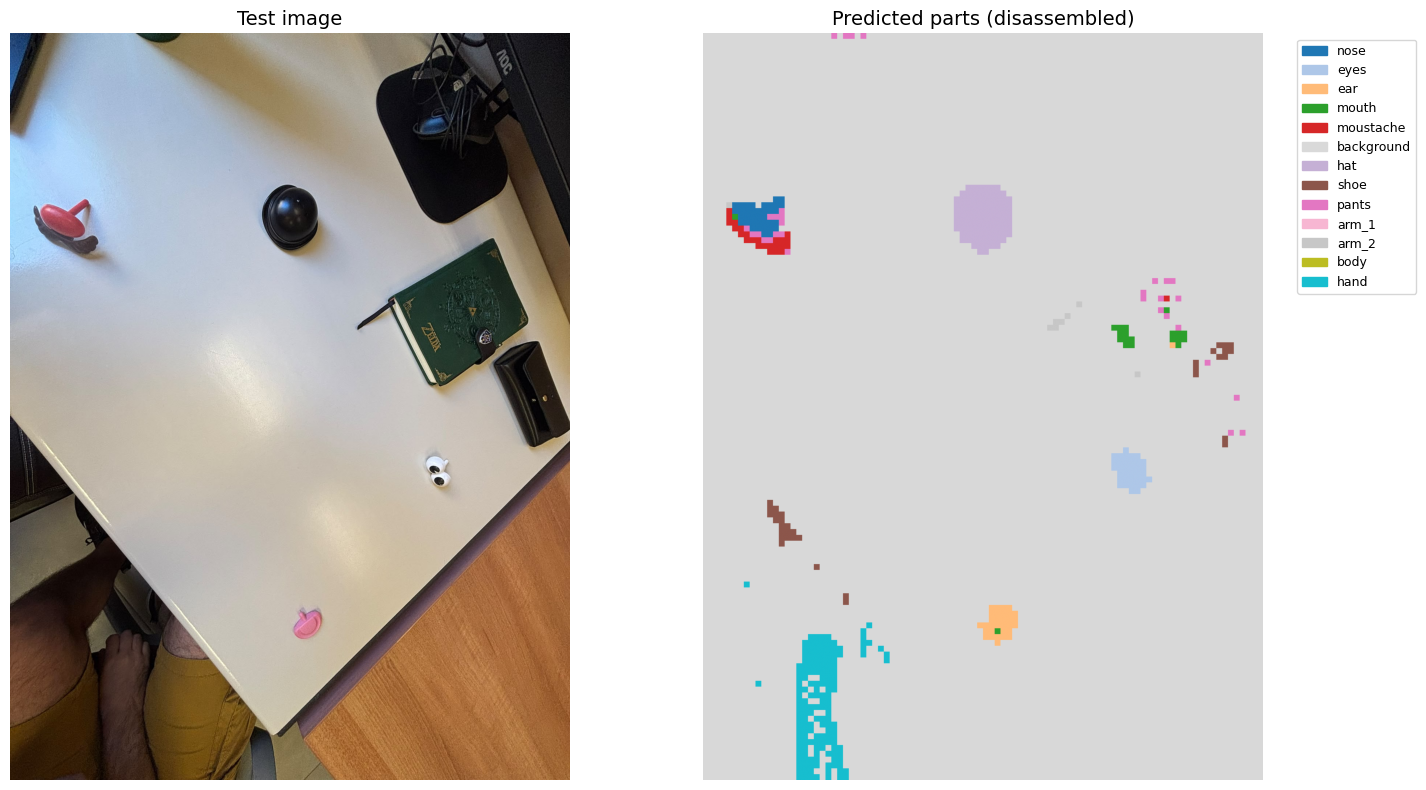

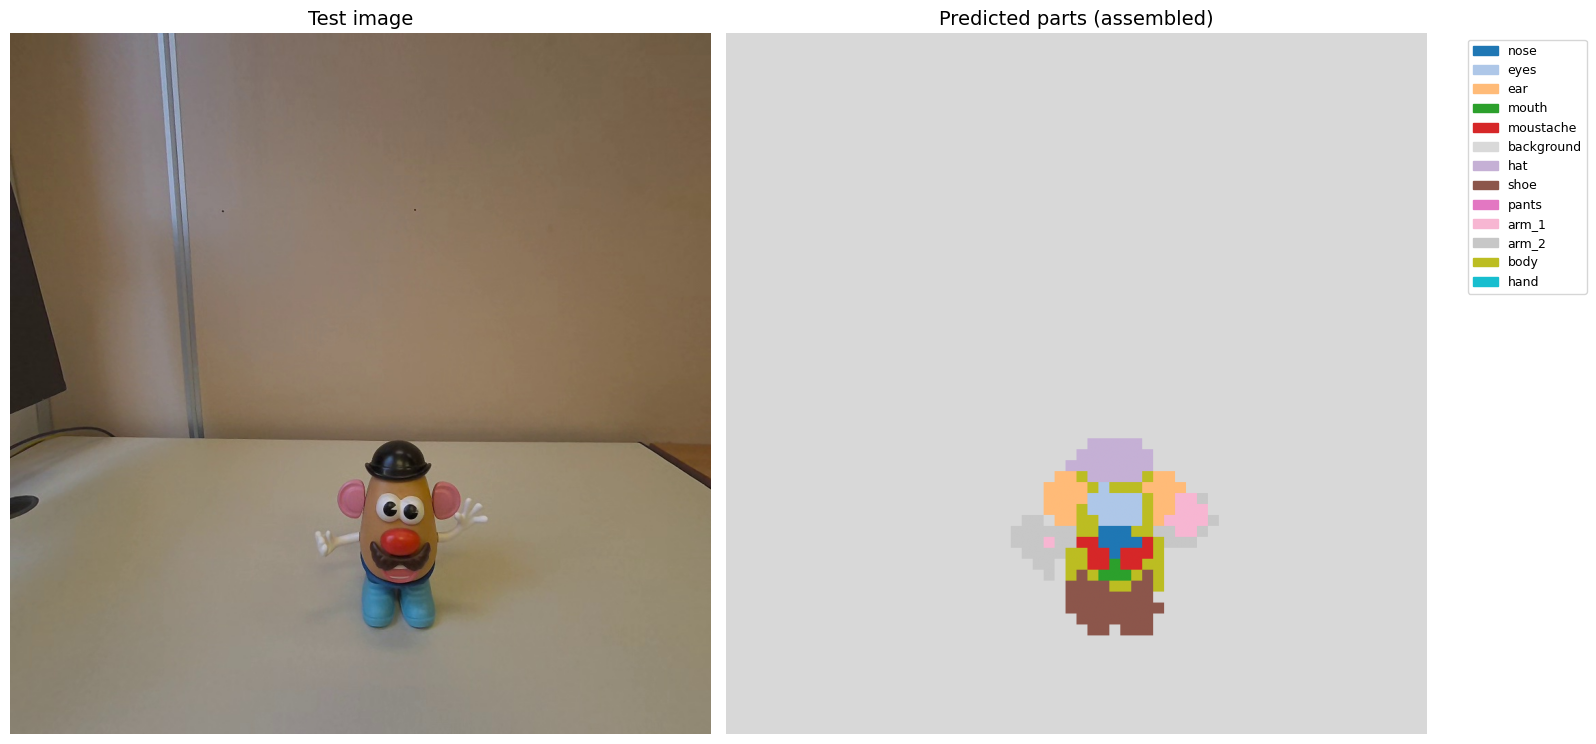

In [ ]:
DISASSEMBLED_FRAME = "../data/extracted_frames/frame_1.jpeg" #prova altri frame problematici
ASSEMBLED_FRAME = "../data/extracted_frames/assembly_1_f0074.jpg"

_ = classify_and_plot(DISASSEMBLED_FRAME, prototypes_final, "(disassembled)")
_ = classify_and_plot(ASSEMBLED_FRAME, prototypes_final, "(assembled)")
